# Task 1: Data Loading 

In [3]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score
)


print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load the actual online payment fraud dataset
df = pd.read_csv("../data/transactions.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0



Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [5]:
print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
display(df.describe(include="all").T)


Data types:
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,6362620.0,NaN,NaN,NaN,243.397246,142.331971,1.0,156.0,239.0,335.0,743.0
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,6362620.0,NaN,NaN,NaN,179861.903549,603858.231463,0.0,13389.57,74871.94,208721.4775,92445516.64
nameOrig,6362620,6353307,C2098525306,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,6362620.0,NaN,NaN,NaN,833883.104074,2888242.673038,0.0,0.0,14208.0,107315.175,59585040.37
newbalanceOrig,6362620.0,NaN,NaN,NaN,855113.668579,2924048.502954,0.0,0.0,0.0,144258.41,49585040.37
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,6362620.0,NaN,NaN,NaN,1100701.66652,3399180.112994,0.0,0.0,132705.665,943036.7075,356015889.35
newbalanceDest,6362620.0,NaN,NaN,NaN,1224996.398202,3674128.94212,0.0,0.0,214661.44,1111909.25,356179278.92
isFraud,6362620.0,NaN,NaN,NaN,0.001291,0.035905,0.0,0.0,0.0,0.0,1.0


In [6]:
print("\nMissing values by column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["isFraud"].value_counts())


Missing values by column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicate rows: 0

Target distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


# Task 2: Data Cleaning

In [7]:
print("Missing values before cleaning:", df.isnull().sum().sum())
print("Duplicates before cleaning:", df.duplicated().sum())

Missing values before cleaning: 0
Duplicates before cleaning: 0


In [8]:
df = df.drop_duplicates().copy()

for col in df.select_dtypes(include="number").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "str"]).columns:
    if df[col].isnull().any():
        modes = df[col].mode()
        if not modes.empty:
            df[col] = df[col].fillna(modes.iloc[0])

print("\nDataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicates:", df.duplicated().sum())


Dataset shape after cleaning: (6362620, 11)
Remaining missing values: 0
Remaining duplicates: 0


In [9]:
# Outlier Analysis

display(
    df.groupby("isFraud")["amount"]
      .describe(percentiles=[0.50, 0.90, 0.95, 0.99, 0.999])
)

print("Maximum transaction amount:", df["amount"].max())

,count,mean,std,min,50%,90%,95%,99%,99.9%,max
isFraud,,,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,74684.72,364373.444,515610.423,1.586064e+06,8.449464e+06,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,441423.44,4521723.512,8006429.040,1.000000e+07,1.000000e+07,10000000.00


Maximum transaction amount: 92445516.64


# Task 3 — Exploratory Data Analysis (EDA)

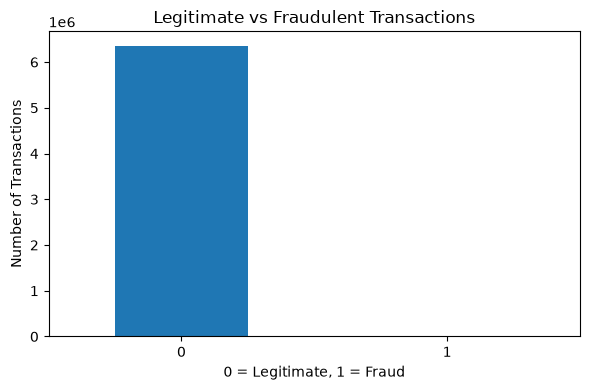

isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


In [10]:
fraud_counts = df["isFraud"].value_counts().sort_index()

fraud_counts.plot(kind="bar", figsize=(6, 4))
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print((df["isFraud"].value_counts(normalize=True) * 100).round(4))

isFraud,0,1
type,,
CASH_IN,100.000,0.000
CASH_OUT,99.816,0.184
DEBIT,100.000,0.000
PAYMENT,100.000,0.000
TRANSFER,99.231,0.769


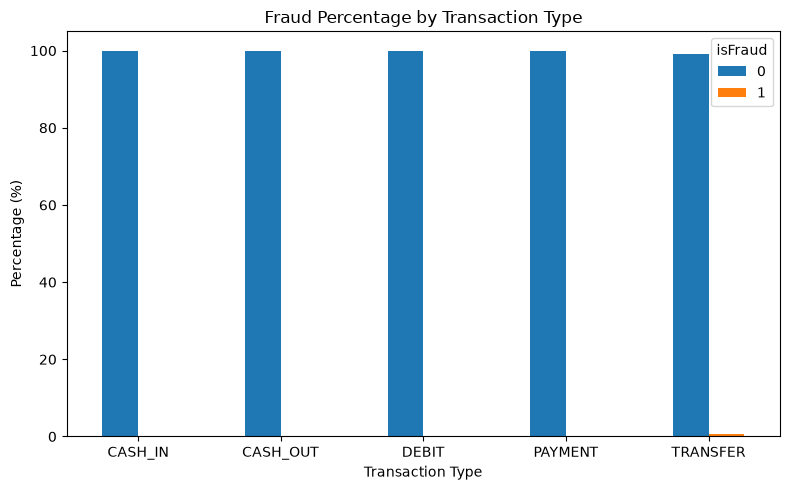

In [11]:
# Transaction Type Analysis

type_fraud = pd.crosstab(
    df["type"], df["isFraud"],
    normalize="index"
) * 100

display(type_fraud.round(3))

type_fraud.plot(kind="bar", figsize=(8, 5))
plt.title("Fraud Percentage by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

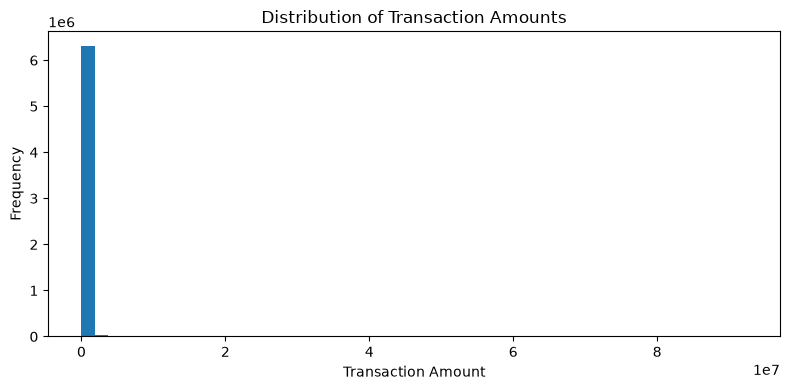

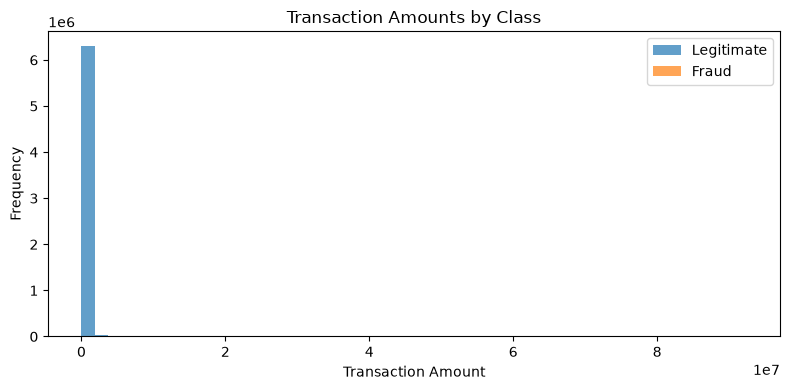

In [12]:
# Transaction Amount Distribution

plt.figure(figsize=(8, 4))
plt.hist(df["amount"], bins=50)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(df.loc[df["isFraud"] == 0, "amount"], bins=50, alpha=0.7,
         label="Legitimate")
plt.hist(df.loc[df["isFraud"] == 1, "amount"], bins=50, alpha=0.7,
         label="Fraud")
plt.title("Transaction Amounts by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

,fraud_count,transaction_count,fraud_rate
step,,,
1,16,2708,0.005908
2,8,1014,0.007890
3,4,552,0.007246
4,10,565,0.017699
5,6,665,0.009023


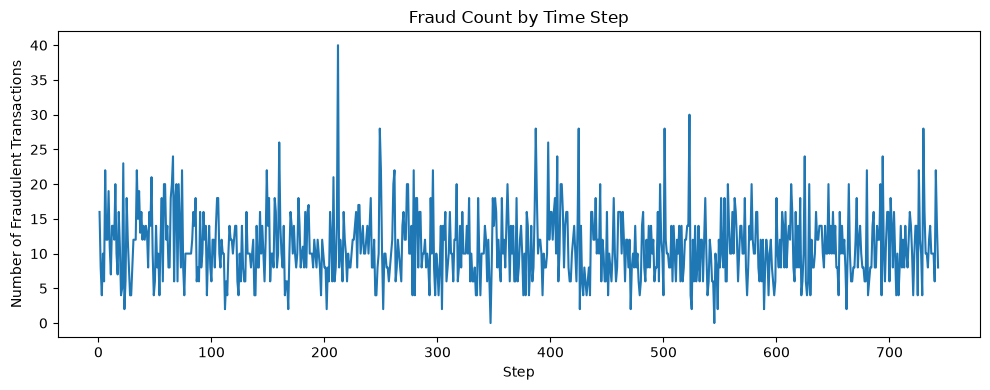

In [13]:
# Fraud Patterns by Step

fraud_by_step = df.groupby("step")["isFraud"].agg(
    fraud_count="sum",
    transaction_count="count",
    fraud_rate="mean"
)

display(fraud_by_step.head())

fraud_by_step["fraud_count"].plot(figsize=(10, 4))
plt.title("Fraud Count by Time Step")
plt.xlabel("Step")
plt.ylabel("Number of Fraudulent Transactions")
plt.tight_layout()
plt.show()

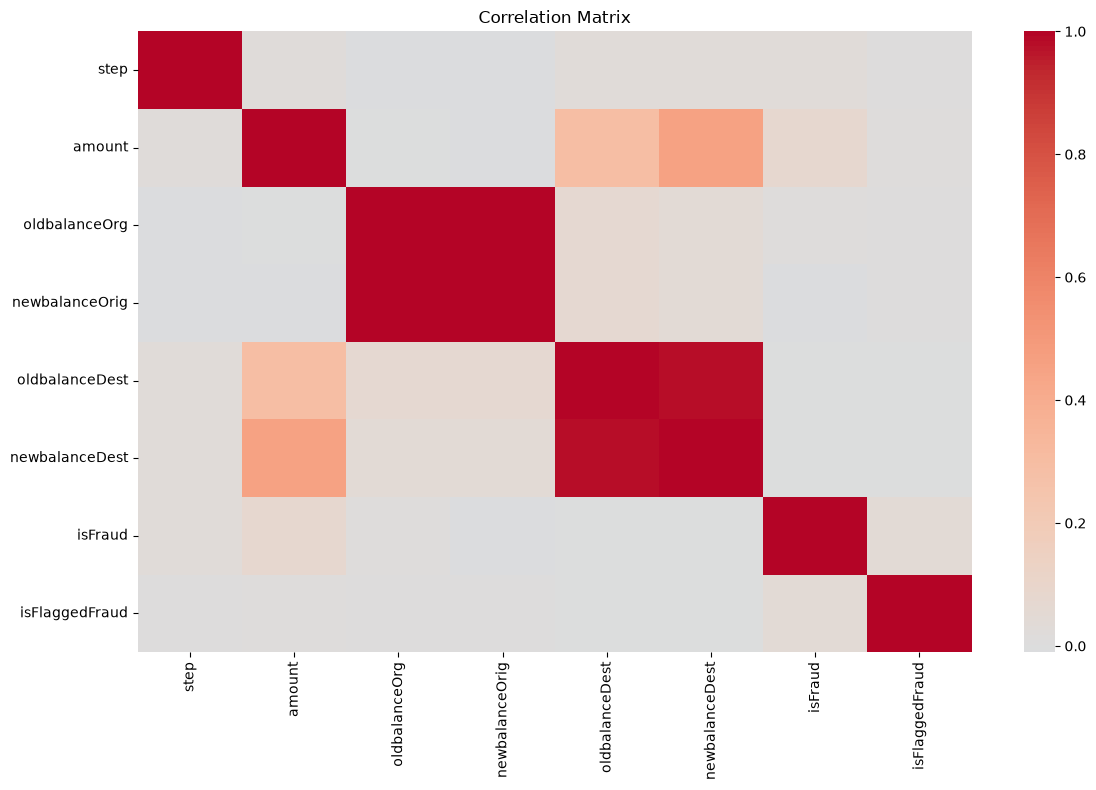

Correlation with isFraud:


,Correlation
isFraud,1.000000
amount,0.076688
isFlaggedFraud,0.044109
step,0.031578
oldbalanceOrg,0.010154
newbalanceDest,0.000535
oldbalanceDest,-0.005885
newbalanceOrig,-0.008148


In [14]:
# Correlation Analysis

numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with isFraud:")
display(
    correlation_matrix["isFraud"]
    .sort_values(ascending=False)
    .to_frame("Correlation")
)

# Task 4 — Feature Engineering 

In [15]:
# Feature Engineering

df["balance_change_orig"] = (
    df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
)

df["balance_change_dest"] = (
    df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
)

df["orig_balance_zero_after"] = (
    df["newbalanceOrig"] == 0
).astype(int)

df["dest_balance_zero_before"] = (
    df["oldbalanceDest"] == 0
).astype(int)

# Define features and target
X = df.drop(
    columns=["isFraud", "isFlaggedFraud", "nameOrig", "nameDest"]
).copy()

y = df["isFraud"].astype(int)

# Encode transaction type
X = pd.get_dummies(X, columns=["type"], dtype=int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature matrix shape: (6362620, 15)
Target shape: (6362620,)

Features:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'balance_change_orig', 'balance_change_dest', 'orig_balance_zero_after', 'dest_balance_zero_before', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


# Task 5: Class Imbalance Analysis

In [21]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy=1.0, random_state=42, k_neighbors=3)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
isFraud
0    5083526
1       6570
Name: count, dtype: int64

After SMOTE:
isFraud
0    5083526
1    5083526
Name: count, dtype: int64


# Task 6 — Train/Test Split and Validation

In [17]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nFraud distribution in training data:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(4))

print("\nFraud distribution in testing data:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(4))

Training data shape: (5090096, 15)
Testing data shape: (1272524, 15)

Fraud distribution in training data:
isFraud
0    5083526
1       6570
Name: count, dtype: int64
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

Fraud distribution in testing data:
isFraud
0    1270881
1       1643
Name: count, dtype: int64
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


In [18]:
# Stratified K-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Number of cross-validation folds:", cv.get_n_splits())

Number of cross-validation folds: 3


In [19]:
#  Train/Test Split

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining fraud rate:", round(y_train.mean() * 100, 4), "%")
print("Testing fraud rate:", round(y_test.mean() * 100, 4), "%")

assert len(X_train) + len(X_test) == len(X)
assert X_train.columns.equals(X_test.columns)

print("\nTrain/test split validation passed.")

Training rows: 5090096
Testing rows: 1272524

Training fraud rate: 0.1291 %
Testing fraud rate: 0.1291 %

Train/test split validation passed.


# Task 7 — Model Training

In [22]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_smote, y_train_smote)
    print("Training completed.")

Training Logistic Regression...
Training completed.
Training Decision Tree...
Training completed.
Training Random Forest...
Training completed.


# Task 8 — Hyperparameter Tuning

In [27]:
tree_pipeline = Pipeline([
    ("smote", SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=3)),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_params = {
    "model__max_depth": [5, 10, 12, 15],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [5, 10, 20]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

tree_search = RandomizedSearchCV(
    tree_pipeline,
    param_distributions=tree_params,
    n_iter=5,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

tree_search.fit(X_train, y_train)

print("Best parameters:", tree_search.best_params_)
print("Best cross-validation PR-AUC:", tree_search.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best parameters: {'model__min_samples_split': 10, 'model__min_samples_leaf': 20, 'model__max_depth': 10}
Best cross-validation PR-AUC: 0.9947424529008151


In [28]:
log_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=3)),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

log_params = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

log_search = RandomizedSearchCV(
    log_pipeline,
    param_distributions=log_params,
    n_iter=4,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

log_search.fit(X_train, y_train)

print("Best parameters:", log_search.best_params_)
print("Best cross-validation PR-AUC:", log_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__class_weight': None, 'model__C': 0.01}
Best cross-validation PR-AUC: 0.7063691370164912


In [29]:
rf_pipeline = Pipeline([
    ("smote", SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=3)),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1))
])

rf_params = {
    "model__n_estimators": [30, 50, 100],
    "model__max_depth": [10, 15, 20],
    "model__min_samples_leaf": [5, 10]
}

rf_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_params,
    n_iter=3,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print("Best cross-validation PR-AUC:", rf_search.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_depth': 15}
Best cross-validation PR-AUC: 0.9968972298825148


In [30]:
tuned_models = {
    "Logistic Regression": log_search.best_estimator_,
    "Decision Tree": tree_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

for name, model in tuned_models.items():
    print(f"{name}: Best CV PR-AUC = ", round(
        {
            "Logistic Regression": log_search.best_score_,
            "Decision Tree": tree_search.best_score_,
            "Random Forest": rf_search.best_score_
        }[name], 4
    ))

Logistic Regression: Best CV PR-AUC =  0.7064
Decision Tree: Best CV PR-AUC =  0.9947
Random Forest: Best CV PR-AUC =  0.9969


# Task 9 — Evaluate Model Performance

In [31]:
results = []

for name, model in tuned_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9954,0.2002,0.8527,0.3243,0.9945,0.6925
1,Decision Tree,1.0000,0.9744,0.9976,0.9859,0.9995,0.9971
2,Random Forest,1.0000,0.9970,0.9976,0.9973,0.9997,0.9987


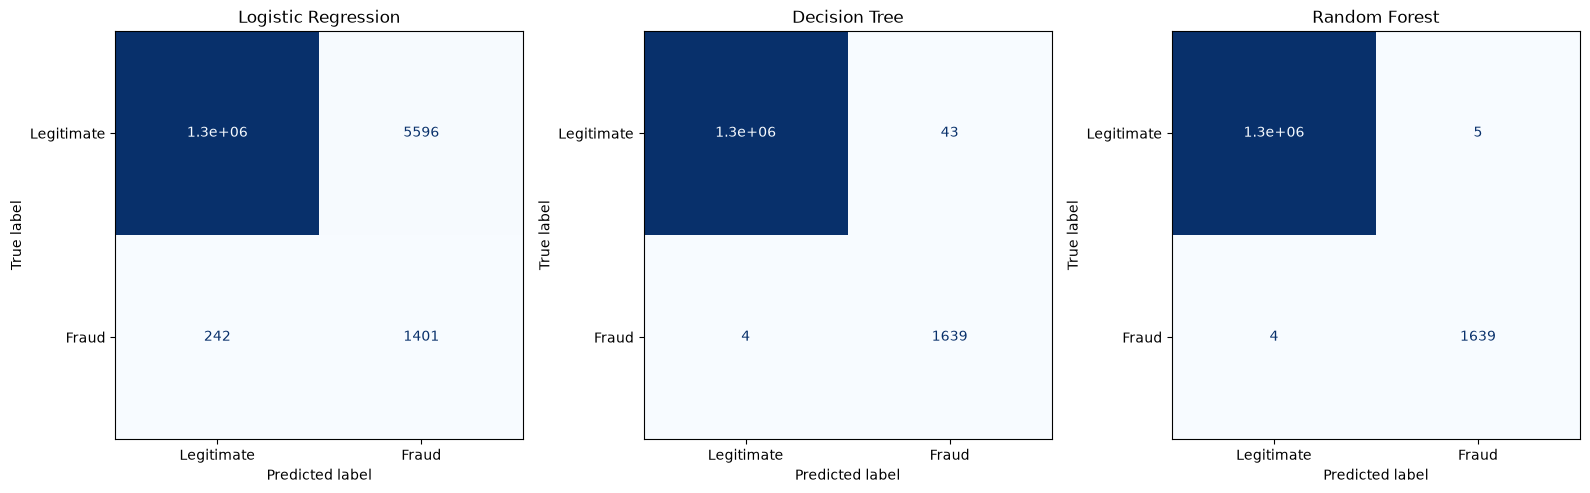

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, tuned_models.items()):

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay(
        confusion_matrix(y_test, y_pred),
        display_labels=["Legitimate", "Fraud"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

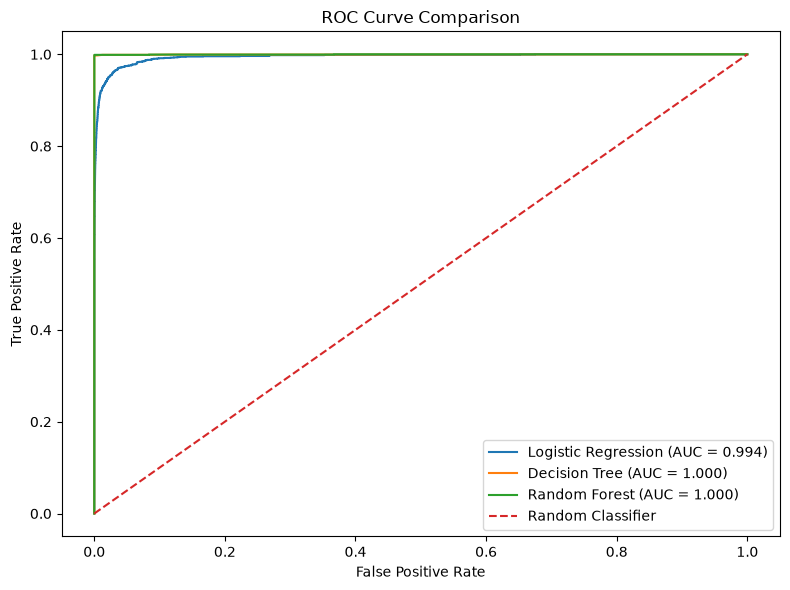

In [33]:
plt.figure(figsize=(8, 6))

for name, model in tuned_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

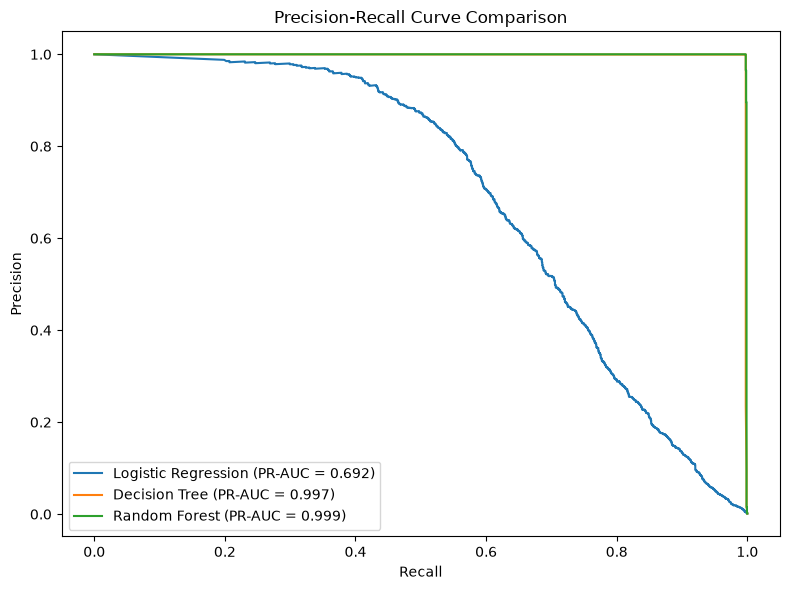

In [34]:
plt.figure(figsize=(8, 6))

for name, model in tuned_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)

    plt.plot(
        recall, precision,
        label=f"{name} (PR-AUC = {average_precision_score(y_test, y_prob):.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

# Task 10 — Model Comparison and Feature Importance

In [53]:
comparison_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    comparison_results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "PR-AUC", ascending=False
    ).round(4)
)

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
2,Random Forest,0.9970,0.9976,0.9973,0.9997,0.9987
1,Decision Tree,0.9744,0.9976,0.9859,0.9995,0.9971
0,Logistic Regression,0.2002,0.8527,0.3243,0.9945,0.6925


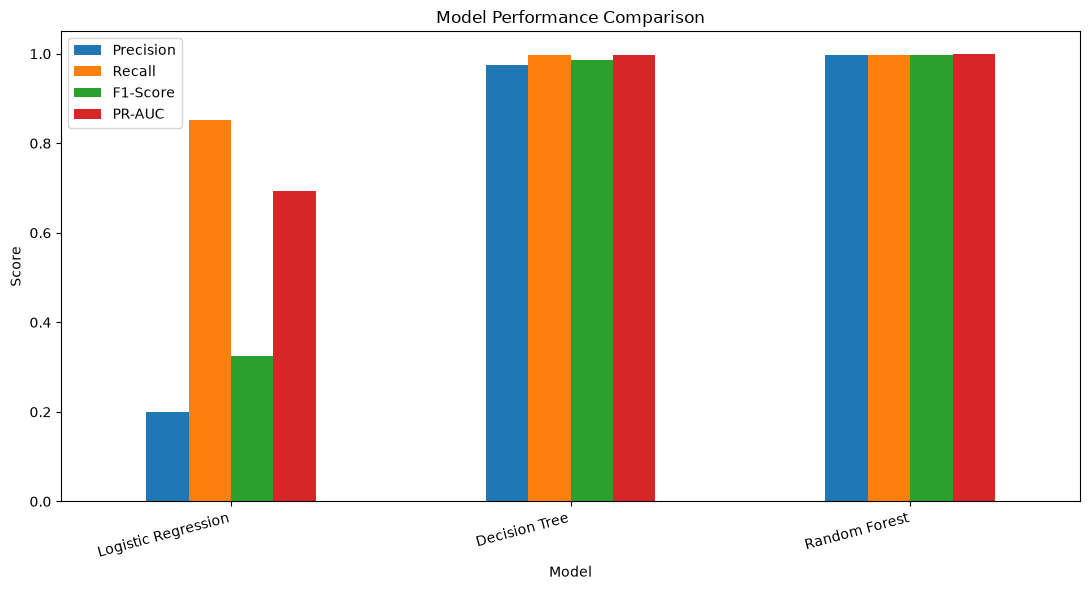

In [54]:
comparison_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score", "PR-AUC"]
].plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [55]:
best_model_name = comparison_df.loc[
    comparison_df["PR-AUC"].idxmax(), "Model"
]

best_model = tuned_models[best_model_name]

print("Best model based on PR-AUC:", best_model_name)
print(
    "PR-AUC:",
    round(
        comparison_df.loc[
            comparison_df["Model"] == best_model_name, "PR-AUC"
        ].iloc[0],
        4
    )
)

Best model based on PR-AUC: Random Forest
PR-AUC: 0.9987



Top 10 features — Decision Tree


,Importance
newbalanceOrig,0.717208
balance_change_orig,0.259812
amount,0.019479
balance_change_dest,0.002069
oldbalanceDest,0.000492
step,0.000443
oldbalanceOrg,0.000311
newbalanceDest,0.000161
type_CASH_OUT,0.000019
dest_balance_zero_before,0.000007


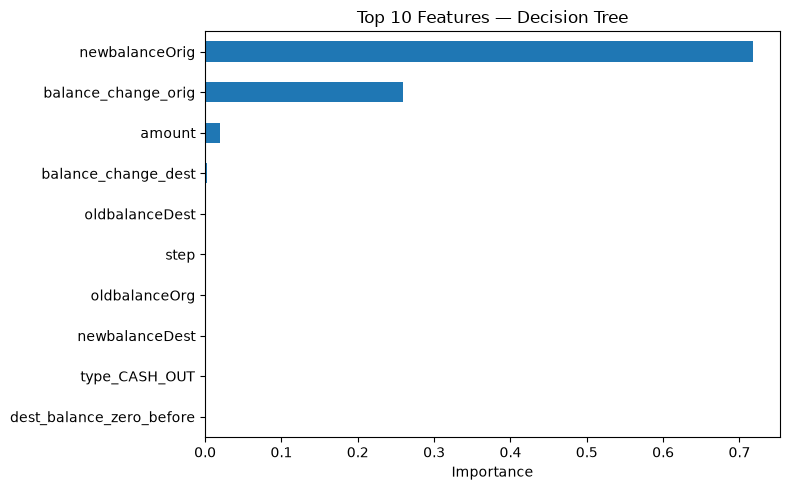


Top 10 features — Random Forest


,Importance
balance_change_orig,0.275004
orig_balance_zero_after,0.134362
newbalanceOrig,0.120344
amount,0.115563
oldbalanceOrg,0.086510
balance_change_dest,0.072441
type_TRANSFER,0.046086
step,0.043895
newbalanceDest,0.031075
type_PAYMENT,0.024896


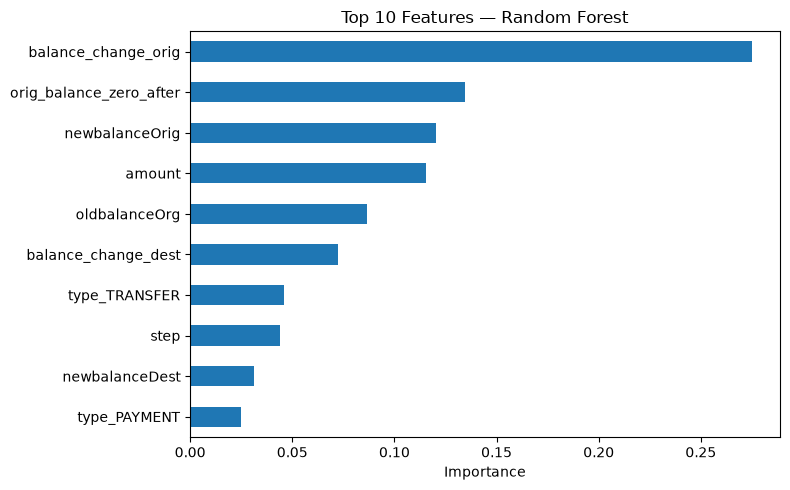

In [56]:
feature_names = X_train.columns

for name in ["Decision Tree", "Random Forest"]:
    model = tuned_models[name]
    classifier = model.named_steps["model"]

    importance = pd.Series(
        classifier.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False)

    print(f"\nTop 10 features — {name}")
    display(importance.head(10).to_frame("Importance"))

    importance.head(10).sort_values().plot(
        kind="barh", figsize=(8, 5)
    )
    plt.title(f"Top 10 Features — {name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

# Task 11 — Save, Reload, and Verify the Best Model

In [57]:
import pickle
import os

os.makedirs("../models", exist_ok=True)

In [59]:
# Check your actual column names
print(results_df.columns.tolist())

['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']


In [60]:
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

best_model = tuned_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [61]:
with open("../models/best_fraud_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")

Model saved successfully!


In [62]:
with open("../models/best_fraud_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [63]:
y_pred_original = best_model.predict(X_test.head(10))
y_pred_loaded = loaded_model.predict(X_test.head(10))

print("Original predictions:", y_pred_original)
print("Loaded predictions:", y_pred_loaded)

print("Predictions match:", (y_pred_original == y_pred_loaded).all())

Original predictions: [0 0 0 0 0 0 0 0 0 0]
Loaded predictions: [0 0 0 0 0 0 0 0 0 0]
Predictions match: True
